# Lab 14 — Inside SmolVLA

**Book sections:** [10.5](../../book/docs/chapters/10-case-studies/groot-smolvla.md),
[11.1](../../book/docs/chapters/11-deployment/latency.md)–[11.3](../../book/docs/chapters/11-deployment/serving.md),
[11.5](../../book/docs/chapters/11-deployment/monitoring.md).

**Goal.** Take a real, pretrained VLA apart. Load SmolVLA (≈450 M parameters) with the `lerobot` library,
feed it a frame from a community LeRobot dataset, and follow the data through every stage: processors,
normalisation, image and language tokens, the VLM prefix, the flow-matching action expert, the action chunk.
Then treat it as a deployment engineer would: measure latency per stage at the tail, choose an execution
horizon, simulate weight quantisation, simulate a policy server shared by a team of robots, and compute an
uncertainty signal.

**Environment.** `lerobot` pins older `numpy`/`transformers` than the course environment, so this lab runs in a
separate one: `scripts/setup_lerobot_env.sh`, then `data/venv-lerobot/bin/jupyter lab`.
**Downloads:** ≈1 GB of weights (SmolVLA + SmolVLM2) and ≈450 MB for one dataset episode (its videos are stored
in multi-episode files). **GPU:** ≈1.3 GB. **Runtime:** ≈6 min after downloads. **Seed:** 0.

In [1]:
import hashlib
import json
import math
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import try_to_load_from_cache

from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.policies.factory import make_pre_post_processors
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy, make_att_2d_masks

torch.manual_seed(0)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, torch.cuda.get_device_name() if dev == "cuda" else "")

device: cuda NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU


## 1. The model
`lerobot/smolvla_base` is the pretrained (not task-fine-tuned) checkpoint. Count parameters by component and
compare with book 10.5: SigLIP vision encoder, pixel-shuffle connector, the first 16 of SmolVLM2's 32 language
layers, and an action expert whose width is 0.75× the VLM's.

In [2]:
t0 = time.time()
policy = SmolVLAPolicy.from_pretrained("lerobot/smolvla_base").to(dev).eval()
print(f"loaded in {time.time() - t0:.0f} s, dtype {next(policy.parameters()).dtype}")
cfg, model = policy.config, policy.model
vwe = model.vlm_with_expert
count = lambda mod: sum(p.numel() for p in mod.parameters())  # noqa: E731
parts = {"vision encoder (SigLIP)": vwe.vlm.model.vision_model, "connector (pixel shuffle + MLP)": vwe.vlm.model.connector,
         f"language model ({cfg.num_vlm_layers} layers)": vwe.vlm.model.text_model, "LM head (unused for actions)": vwe.vlm.lm_head,
         "action expert": vwe.lm_expert}
for name, mod in parts.items():
    print(f"{name:34s} {count(mod) / 1e6:7.1f} M")
print(f"{'total':34s} {count(policy) / 1e6:7.1f} M  ({count(policy) * 2 / 1e9:.2f} GB in bf16)")
print(f"\ninputs : {list(cfg.input_features)}\noutputs: {list(cfg.output_features)}")
print(f"chunk {cfg.chunk_size} actions, {cfg.num_steps} flow steps, state/action padded to {cfg.max_state_dim}, "
      f"images resized+padded to {cfg.resize_imgs_with_padding}, expert attention: {cfg.attention_mode} "
      f"(self-attention every {cfg.self_attn_every_n_layers} layers)")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Reducing the number of VLM layers to 16 ...


loaded in 7 s, dtype torch.bfloat16
vision encoder (SigLIP)               86.4 M
connector (pixel shuffle + MLP)       11.8 M
language model (16 layers)           204.6 M
LM head (unused for actions)          47.3 M
action expert                         98.2 M
total                                450.0 M  (0.90 GB in bf16)

inputs : ['observation.state', 'observation.images.camera1', 'observation.images.camera2', 'observation.images.camera3']
outputs: ['action']
chunk 50 actions, 10 flow steps, state/action padded to 32, images resized+padded to (512, 512), expert attention: cross_attn (self-attention every 2 layers)


## 2. A frame from a community dataset
`lerobot/svla_so100_pickplace`: a low-cost SO-100 arm picking a cube, two cameras, 30 fps. `delta_timestamps`
asks the dataset to return, with each frame, the next 50 actions — exactly the training target of a chunked policy.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

454 frames at 30 fps; features: ['action', 'observation.state', 'observation.images.top', 'observation.images.wrist', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index']
  observation.images.top       (3, 480, 640)
  observation.images.wrist     (3, 480, 640)
  action                       (50, 6)
  observation.state            (6,)
  timestamp                    ()
  frame_index                  ()
  episode_index                ()
  index                        ()
  task_index                   ()
  action_is_pad                (50,)
  task                         'Pick up the cube and place it in the box.'


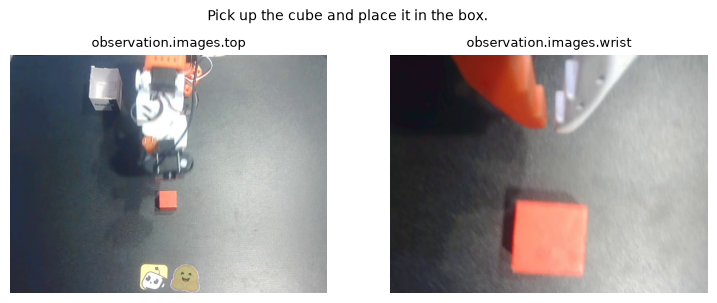

In [3]:
H_A = cfg.chunk_size
ds = LeRobotDataset("lerobot/svla_so100_pickplace", episodes=[0],
                    delta_timestamps={"action": [i / 30 for i in range(H_A)]})
print(f"{ds.num_frames} frames at {ds.fps} fps; features: {list(ds.meta.features)}")
item = ds[100]
for k, v in item.items():
    print(f"  {k:28s} {tuple(v.shape) if torch.is_tensor(v) else repr(v)}")
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, k in zip(axs, ["observation.images.top", "observation.images.wrist"]):
    ax.imshow(item[k].permute(1, 2, 0)); ax.set_title(k, fontsize=9); ax.axis("off")
plt.suptitle(item["task"].strip(), fontsize=10); plt.show()

## 3. Processors and normalisation statistics
A LeRobot policy ships with a **preprocessor** (rename cameras, add the batch dimension, tokenise the task,
move to the device, normalise) and a **postprocessor** (un-normalise, move to the CPU). The base checkpoint's
camera slots are called `camera1..3`, so we map our cameras onto them. First, use the processors exactly as
shipped:

In [4]:
RENAME = {"observation.images.top": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2"}
KEYS = ["observation.images.top", "observation.images.wrist", "observation.state", "task"]
pre0, post0 = make_pre_post_processors(cfg, pretrained_path="lerobot/smolvla_base",
                                       preprocessor_overrides={"rename_observations_processor": {"rename_map": RENAME}})
print("preprocessor :", [type(s).__name__ for s in pre0.steps])
print("postprocessor:", [type(s).__name__ for s in post0.steps])
obs = {k: item[k] for k in KEYS}
noise = torch.randn(1, H_A, cfg.max_action_dim, generator=torch.Generator().manual_seed(0)).to(dev)
policy.reset()
a0 = post0(policy.predict_action_chunk(pre0(obs), noise=noise))[0].cpu()
print("first predicted action:", a0[0].numpy().round(2))
print("recorded action       :", item["action"][0].numpy().round(2))

preprocessor : ['RenameObservationsProcessorStep', 'AddBatchDimensionProcessorStep', 'NewLineTaskProcessorStep', 'TokenizerProcessorStep', 'DeviceProcessorStep', 'NormalizerProcessorStep']
postprocessor: ['UnnormalizerProcessorStep', 'DeviceProcessorStep']


first predicted action: [-1.11 -0.4  -0.2   0.23  2.22  0.12]
recorded action       : [ -0.79 -34.1   42.45  54.05  82.     2.24]


The prediction is in **normalised** units while the recorded actions are joint angles in degrees: the base
checkpoint carries no statistics for this robot, so its (un)normaliser is the identity. Normalisation
statistics belong to the *dataset and robot*, and must travel with every checkpoint (book 8.3, 9.3). Plug in the
dataset's:

In [5]:
STATS = ds.meta.stats
pre, post = make_pre_post_processors(
    cfg, pretrained_path="lerobot/smolvla_base",
    preprocessor_overrides={"rename_observations_processor": {"rename_map": RENAME}, "normalizer_processor": {"stats": STATS}},
    postprocessor_overrides={"unnormalizer_processor": {"stats": STATS}})


def predict(o, noise=noise, steps=None):
    policy.reset()
    if steps is not None:
        policy.config.num_steps = steps
    out = post(policy.predict_action_chunk(pre(o), noise=noise)).cpu()
    policy.config.num_steps = 10
    return out


batch = pre(obs)
for k, v in batch.items():
    if torch.is_tensor(v):
        print(f"  {k:38s} {str(tuple(v.shape)):18s} {v.dtype}")
pred = predict(obs)[0]
print("first predicted action:", pred[0].numpy().round(1), "\nrecorded action       :", item["action"][0].numpy().round(1))

  observation.images.camera1             (1, 3, 480, 640)   torch.float32
  observation.images.camera2             (1, 3, 480, 640)   torch.float32
  observation.state                      (1, 6)             torch.float32
  observation.language.tokens            (1, 48)            torch.int64
  observation.language.attention_mask    (1, 48)            torch.bool
first predicted action: [ -3.3 -48.4  43.4  53.3  82.4   1.3] 
recorded action       : [ -0.8 -34.1  42.5  54.1  82.    2.2]


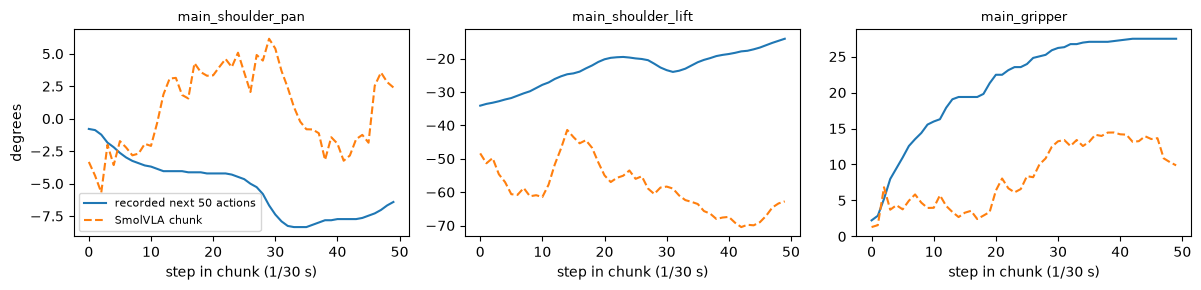

mean |chunk error| over 17 frames, per joint (degrees): [15.1 22.6  7.7  9.4  7.6  5.2]
action std per joint (degrees)                   : [28.  35.  21.5 16.9 12.5  9.5]


In [6]:
names = ds.meta.features["action"]["names"]
names = names if isinstance(names, list) else [f"joint {i}" for i in range(6)]
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for ax, j in zip(axs, [0, 1, 5]):
    ax.plot(item["action"][:, j], label="recorded next 50 actions")
    ax.plot(pred[:, j], "--", label="SmolVLA chunk")
    ax.set_title(str(names[j]), fontsize=9); ax.set_xlabel("step in chunk (1/30 s)")
axs[0].set_ylabel("degrees"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

errs = []
for t in range(0, ds.num_frames - H_A, 25):
    it = ds[t]
    errs.append((predict({k: it[k] for k in KEYS})[0] - it["action"]).abs().mean(0))
errs = torch.stack(errs)
std = torch.as_tensor(STATS["action"]["std"]).float()
print(f"mean |chunk error| over {len(errs)} frames, per joint (degrees):", errs.mean(0).numpy().round(1))
print("action std per joint (degrees)                   :", std.numpy().round(1))

The base model's chunks follow the recorded motion roughly — errors are a fraction of each joint's spread —
without any fine-tuning on this dataset. A fine-tuned checkpoint would do much better; that is what
post-training is for (book 9.1).

## 4. Counting tokens
Each camera image is resized and padded to 512×512, encoded by SigLIP into 32×32 patches, and reduced by the
connector's pixel shuffle to 64 tokens. Then come the instruction's tokens (padded to 48) and one state token.

In [7]:
with torch.no_grad():
    images, img_masks = policy.prepare_images(batch)
    state = policy.prepare_state(batch)
    per_cam = vwe.embed_image(images[0]).shape[1]
    emb, pad, att = model.embed_prefix(images, img_masks, batch["observation.language.tokens"],
                                       batch["observation.language.attention_mask"], state=state)
n_lang = int(batch["observation.language.attention_mask"].sum())
n_special = int(pad.sum()) - 2 * per_cam - n_lang - 1
print(f"prepared images: {[tuple(i.shape) for i in images]}")
print(f"prefix: {emb.shape[1]} positions, {int(pad.sum())} real = 2 cameras x {per_cam} image tokens + {n_lang} "
      f"instruction tokens + 1 state token + {n_special} image start/end tokens; width {emb.shape[-1]}")
print(f"action expert input: {H_A} action tokens of width {vwe.expert_hidden_size}")

prepared images: [(1, 3, 512, 512), (1, 3, 512, 512)]
prefix: 177 positions, 141 real = 2 cameras x 64 image tokens + 12 instruction tokens + 1 state token + 0 image start/end tokens; width 960
action expert input: 50 action tokens of width 720


## 5. Latency, stage by stage (book 11.1)
Time each stage 30 times at batch 1 and report the median, p90, p99 and maximum. Note LeRobot's convention:
flow time runs from 1 (noise) to 0 (actions), the reverse of the book's; the integration is the same.

In [8]:
class StageTimer:
    def __init__(self):
        self.samples = defaultdict(list)

    def measure(self, stage, fn):
        t0 = time.perf_counter()
        out = fn()
        if dev == "cuda":
            torch.cuda.synchronize()
        self.samples[stage].append((time.perf_counter() - t0) * 1000)
        return out

    def report(self):
        for stage, v in self.samples.items():
            v = np.array(v)
            print(f"{stage:22s} p50 {np.percentile(v, 50):7.1f}  p90 {np.percentile(v, 90):7.1f}  "
                  f"p99 {np.percentile(v, 99):7.1f}  max {v.max():7.1f} ms")


def one_chunk(T, steps=10):
    b = T.measure("preprocess", lambda: pre(obs))
    ims, ms = T.measure("prepare images", lambda: policy.prepare_images(b))
    st = policy.prepare_state(b)
    e, p_, a_ = T.measure("vision + embed prefix", lambda: model.embed_prefix(
        ims, ms, b["observation.language.tokens"], b["observation.language.attention_mask"], state=st))
    _, kv = T.measure("VLM prefill (cached)", lambda: vwe.forward(
        attention_mask=make_att_2d_masks(p_, a_), position_ids=torch.cumsum(p_, 1) - 1, past_key_values=None,
        inputs_embeds=[e, None], use_cache=True))

    def expert():
        x = noise.clone()
        for i in range(steps):
            x = x - model.denoise_step(p_, kv, x, torch.full((1,), 1 - i / steps, device=dev)) / steps
        return x
    x = T.measure(f"action expert x {steps}", expert)
    return T.measure("postprocess", lambda: post(x[:, :, :6].float()))


with torch.no_grad():
    for _ in range(3):
        one_chunk(StageTimer())                                     # warm-up
    T = StageTimer()
    for _ in range(30):
        one_chunk(T)
T.report()
total = np.sum([np.array(v) for v in T.samples.values()], axis=0)
p99 = np.percentile(total, 99)
print(f"\nend-to-end p50 {np.median(total):.0f} ms, p99 {p99:.0f} ms")
for hz in (10, 30, 50):
    print(f"at {hz:2d} Hz a synchronous executor needs H_e >= {math.ceil(p99 / 1000 * hz):3d} actions per chunk "
          f"({'fits' if math.ceil(p99 / 1000 * hz) <= H_A else 'exceeds'} the {H_A}-action chunk)")

preprocess             p50     1.5  p90     1.6  p99     1.8  max     1.8 ms
prepare images         p50     0.2  p90     0.2  p99     0.2  max     0.2 ms
vision + embed prefix  p50    24.4  p90    25.2  p99    25.6  max    25.7 ms
VLM prefill (cached)   p50     9.9  p90    10.3  p99    10.5  max    10.5 ms
action expert x 10     p50    89.5  p90    91.1  p99    91.9  max    92.0 ms
postprocess            p50     0.1  p90     0.1  p99     0.1  max     0.1 ms

end-to-end p50 126 ms, p99 128 ms
at 10 Hz a synchronous executor needs H_e >=   2 actions per chunk (fits the 50-action chunk)
at 30 Hz a synchronous executor needs H_e >=   4 actions per chunk (fits the 50-action chunk)
at 50 Hz a synchronous executor needs H_e >=   7 actions per chunk (fits the 50-action chunk)


Compare the split with book 6.6 and 8.7: the vision encoder and the prefix run once per chunk; the expert runs
`num_steps` times. In the committed run (a 6 GB laptop GPU) the ten expert passes take about 70% of the 126 ms
total — more than SigLIP and the cached prefill together. Each pass is small (50 action tokens) but goes through
16 expert layers at batch 1, where kernel launches and Python dominate the arithmetic. The cost model of book 6.6
predicts *which* parts scale with what; only a measurement tells you which part dominates on your hardware.
Reducing flow steps trades accuracy for time — measure how far the chunk moves:

In [9]:
ref = predict(obs, steps=10)[0]
for steps in (1, 2, 4, 10, 20):
    with torch.no_grad():
        Ts = StageTimer()
        for _ in range(5):
            Ts.measure("chunk", lambda: predict(obs, steps=steps))
    dif = (predict(obs, steps=steps)[0] - ref).abs().mean().item()
    print(f"{steps:2d} flow steps: {np.median(Ts.samples['chunk']):6.0f} ms per chunk, mean |change| vs 10 steps {dif:5.2f} deg")

 1 flow steps:     52 ms per chunk, mean |change| vs 10 steps  3.67 deg


 2 flow steps:     61 ms per chunk, mean |change| vs 10 steps  2.49 deg


 4 flow steps:     77 ms per chunk, mean |change| vs 10 steps  1.15 deg


10 flow steps:    129 ms per chunk, mean |change| vs 10 steps  0.00 deg


20 flow steps:    218 ms per chunk, mean |change| vs 10 steps  0.33 deg


## 6. Weight quantisation, simulated (book 11.2)
Quantise every linear weight of the language model and the action expert, group-wise (64 weights per scale),
to int8 and int4, then dequantise back to bf16 ("fake quantisation"). This shows the *accuracy* effect with the
same noise; it gives no speed-up — that needs low-bit kernels — and the memory column is computed, not measured.

In [10]:
def fake_quant_(w, bits, group=64):
    q = 2 ** (bits - 1) - 1
    g = w.float().reshape(-1, group)
    s = g.abs().amax(1, keepdim=True).clamp(min=1e-8) / q
    w.copy_((torch.clamp(torch.round(g / s), -q - 1, q) * s).reshape(w.shape).to(w.dtype))


linears = [m for root in (vwe.vlm.model.text_model, vwe.lm_expert) for m in root.modules() if isinstance(m, torch.nn.Linear)]
backup = [l.weight.detach().cpu().clone() for l in linears]
n_q = sum(l.weight.numel() for l in linears)
n_rest = count(policy) - n_q - count(vwe.vlm.lm_head)
for bits in (16, 8, 4):
    if bits < 16:
        with torch.no_grad():
            for l, b in zip(linears, backup):
                l.weight.copy_(b.to(l.weight.device)); fake_quant_(l.weight, bits)
    mem = (n_q * (bits / 8 + (2 / 64 if bits < 16 else 0)) + n_rest * 2) / 1e9
    chunks = torch.stack([predict({k: ds[t][k] for k in KEYS})[0] for t in (0, 100, 200, 300)])
    if bits == 16:
        ref_chunks = chunks
    print(f"{'bf16' if bits == 16 else f'int{bits}':5s} weights ≈ {mem:.2f} GB; mean |chunk change| vs bf16: "
          f"{(chunks - ref_chunks).abs().mean():.2f} deg")
with torch.no_grad():
    for l, b in zip(linears, backup):
        l.weight.copy_(b.to(l.weight.device))

bf16  weights ≈ 0.81 GB; mean |chunk change| vs bf16: 0.00 deg


int8  weights ≈ 0.56 GB; mean |chunk change| vs bf16: 0.19 deg


int4  weights ≈ 0.43 GB; mean |chunk change| vs bf16: 2.73 deg


**Reading §6.** int8 moves the chunks by a fraction of a degree, int4 by a few degrees — small next to the
model's own error on this dataset (§3) and next to the spread between noise samples (§8), but not negligible for
precise tasks. Validate in closed loop before deploying int4 (book 11.2).

## 7. A policy server for a team (book 11.3)
Measure the time for one chunk at batch sizes 1–8, then simulate $N$ robots that each execute $H_e=8$ actions
at 10 Hz (a new chunk every 0.8 s, requested when 4 actions remain, so a response has 0.4 s before the robot
runs dry). The server waits up to a batching window $w$ for more requests, then serves them all in one pass.

{1: '125 ms', 2: '169 ms', 4: '280 ms', 8: '543 ms'}
1 robots, window 50 ms: request→chunk p50  125 ms, p99  125 ms, missed  0.0%, GPU busy  16%
2 robots, window 50 ms: request→chunk p50  125 ms, p99  125 ms, missed  0.0%, GPU busy  31%
3 robots, window 50 ms: request→chunk p50  125 ms, p99  125 ms, missed  0.0%, GPU busy  47%
4 robots, window 50 ms: request→chunk p50  169 ms, p99  189 ms, missed  0.0%, GPU busy  52%
5 robots, window 50 ms: request→chunk p50  125 ms, p99  189 ms, missed  0.0%, GPU busy  68%
6 robots, window 50 ms: request→chunk p50  169 ms, p99  352 ms, missed  0.0%, GPU busy  73%
7 robots, window 50 ms: request→chunk p50  193 ms, p99  327 ms, missed  0.0%, GPU busy  80%
8 robots, window 50 ms: request→chunk p50  197 ms, p99  342 ms, missed  0.0%, GPU busy  86%


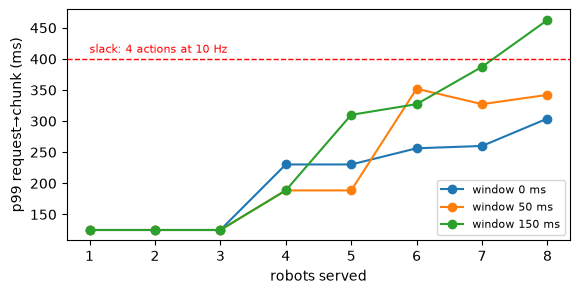

In [11]:
def batch_of(B):
    b = pre(obs)
    out = {k: v.repeat(B, *[1] * (v.dim() - 1)) for k, v in b.items() if torch.is_tensor(v)}
    out["task"] = b["task"] * B
    return out


t_batch = {}
with torch.no_grad():
    for B in (1, 2, 4, 8):
        bb, ts = batch_of(B), []
        for _ in range(5):
            policy.reset(); t0 = time.perf_counter(); policy.predict_action_chunk(bb)
            if dev == "cuda":
                torch.cuda.synchronize()
            ts.append(time.perf_counter() - t0)
        t_batch[B] = float(np.median(ts))
print({B: f"{t * 1000:.0f} ms" for B, t in t_batch.items()})
tb = lambda B: float(np.interp(B, list(t_batch), list(t_batch.values())))  # noqa: E731


def simulate(n_robots, window, period=0.8, slack=0.4, horizon=60.0, seed=0):
    rng = np.random.default_rng(seed)
    nxt = list(rng.uniform(0, period, n_robots))            # next request time of each robot
    t, waits, busy = 0.0, [], 0.0
    while t < horizon:
        first = min(nxt)
        t = max(t, first)
        cutoff = t + window                                   # batch everything that arrives within the window
        group = [i for i in range(n_robots) if nxt[i] <= cutoff][:8]
        start = max(t, max(nxt[i] for i in group))
        dt = tb(len(group))
        done = start + dt
        busy += dt
        for i in group:
            waits.append(done - nxt[i])
            nxt[i] += period
        t = done
    w = np.array(waits)
    return w, (w > slack).mean(), busy / t


fig, ax = plt.subplots(figsize=(6.5, 3))
for window in (0.0, 0.05, 0.15):
    p99s = []
    for n in range(1, 9):
        w, miss, util = simulate(n, window)
        p99s.append(np.percentile(w, 99))
        if window == 0.05:
            print(f"{n} robots, window 50 ms: request→chunk p50 {np.median(w) * 1000:4.0f} ms, p99 "
                  f"{np.percentile(w, 99) * 1000:4.0f} ms, missed {miss:5.1%}, GPU busy {util:4.0%}")
    ax.plot(range(1, 9), np.array(p99s) * 1000, "o-", label=f"window {window * 1000:.0f} ms")
ax.axhline(400, color="red", ls="--", lw=1); ax.text(1, 410, "slack: 4 actions at 10 Hz", color="red", fontsize=8)
ax.set_xlabel("robots served"); ax.set_ylabel("p99 request→chunk (ms)"); ax.legend(fontsize=8); plt.show()

**Reading §7.** A chunk for 8 robots costs about four times one for a single robot, not eight: batching helps,
but less than the bandwidth argument of book 11.3 suggests, because two 512-pixel images per robot make the
prefix compute-heavy. In the simulation one laptop GPU serves 8 robots without missed deadlines, at high load,
and with a p99 latency close to the 0.4 s slack — the next robot, a slower GPU or a longer prefix would break it.

## 8. An uncertainty signal and a log record (book 11.5)
Sample 8 chunks with different noise for the same observation and measure their spread, at a few frames of the
episode. Then write the record a deployment would log for each chunk.

In [12]:
spread = []
for t in range(0, ds.num_frames - H_A, 50):
    o = {k: ds[t][k] for k in KEYS}
    cs = torch.stack([predict(o, noise=torch.randn(1, H_A, cfg.max_action_dim, generator=torch.Generator().manual_seed(s)).to(dev))[0]
                      for s in range(8)])
    spread.append((t, cs.std(0).mean().item()))
print("frame : mean std over 8 sampled chunks (deg)")
for t, s in spread:
    print(f"{t:5d} : {s:5.2f}")
ckpt = try_to_load_from_cache("lerobot/smolvla_base", "model.safetensors")
weights_hash = hashlib.sha256(Path(ckpt).read_bytes()).hexdigest()[:16] if isinstance(ckpt, str) else "unknown"
record = {"t_obs": float(item["timestamp"]), "task": item["task"].strip(), "model": "lerobot/smolvla_base",
          "weights_sha256": weights_hash, "stats": "svla_so100_pickplace meta/stats.json",
          "num_steps": cfg.num_steps, "chunk": pred[:2].numpy().round(2).tolist(), "latency_ms_p50": float(np.median(total))}
print(json.dumps(record)[:400], "…")

frame : mean std over 8 sampled chunks (deg)
    0 :  4.02
   50 :  4.05
  100 :  6.21
  150 :  5.86
  200 :  5.55
  250 :  5.08
  300 :  4.08
  350 :  2.24
  400 :  3.61


{"t_obs": 3.3333332538604736, "task": "Pick up the cube and place it in the box.", "model": "lerobot/smolvla_base", "weights_sha256": "7cd549ac2351fb06", "stats": "svla_so100_pickplace meta/stats.json", "num_steps": 10, "chunk": [[-3.3299999237060547, -48.38999938964844, 43.36000061035156, 53.34000015258789, 82.36000061035156, 1.2999999523162842], [-4.389999866485596, -51.36000061035156, 42.569999 …


## Exercises
1. **Fine-tune.** With the `lerobot` training script, fine-tune `smolvla_base` on a few episodes of this
   dataset (book 9.4) and repeat §3. How much does the chunk error drop?
2. **Fewer image tokens.** Feed only the top camera. How do the prefix length, latency and the chunk change?
3. **Asynchronous execution.** Using §5's p99 and 30 Hz control, compute the staleness of the first new action
   with asynchronous execution, and the smallest refill threshold that never starves the controller.
4. **Real quantisation.** If `bitsandbytes` supports your GPU, load the language model in 8-bit and measure
   memory and latency; compare with §6.
5. **Server policy.** Replace "first come, first served" in `simulate` by "most urgent first" (smallest
   remaining queue). When does it help?